# Superstore Sales and Business Performance Analysis
Original exploratory analysis, statistical testing, regression, classification, and clustering.


## Run this notebook from GitHub or Google Colab
Run all cells from the top. The next cell retrieves any missing datasets from the public portfolio repository. Internet access is required for first-time downloads.


In [ ]:
# Portfolio setup: works in Google Colab and from a local project checkout.
# Requires the project datasets to be published in this GitHub repository.
from pathlib import Path
from urllib.request import urlretrieve
import os

PROJECT_FILES = ['data/Superstore.csv', 'superstore_cleaned.csv', 'superstore_cleaned_encoded.csv', 'superstore_encoded.csv']
BASE_URL = "https://raw.githubusercontent.com/josephine-ms/josephine-ms.github.io/main/Projects/Superstore_Sales/"
for filename in PROJECT_FILES:
    path = Path(filename)
    if not path.is_file():
        path.parent.mkdir(parents=True, exist_ok=True)
        try:
            urlretrieve(BASE_URL + filename, path)
            print("Downloaded:", filename)
        except Exception as exc:
            raise RuntimeError(
                f"Could not retrieve {filename} from the public GitHub repository. "
                "Confirm that the file was uploaded and the repository is public."
            ) from exc
print("Dataset files available.")


# Hands-on data analysis with Pandas - Final Project
Project Goal:
To conduct a comprehensive exploratory data analysis on a real-world dataset, utilizing various statistical techniques, visualization methods, and advanced methods to uncover insights, patterns, and relationships between variables. 

# Uncovering Sales Trends and Business Patterns in a Retail Superstore Dataset
In today’s highly competitive retail environment, gaining deep insights into customer behavior, sales performance, and profitability is crucial for making informed business decisions. This project aims to conduct a comprehensive Exploratory Data Analysis (EDA) on the Superstore Sales dataset,  a real-world retail dataset representing a fictional U.S.-based store. The primary objective is to uncover actionable insights by analyzing patterns and trends in order management, product performance, and regional profitability. These findings will help highlight potential areas for operational improvement and strategic growth.

# 1.Dataset Selection

The Superstore Sales dataset is sufficiently large and comprehensive for performing exploratory data analysis in a retail context. It is dowloaded from https://www.tableau.com/sites/default/files/2021-05/Sample%20-%20Superstore.xls
It contains over 9,000 records with detailed information on customer transactions, including variables such as sales, profit, discount, quantity, product category, sub-category, shipping mode, order date, and customer location.
The dataset is well-aligned with the objectives of this project, which involve uncovering patterns and insights into order management, product performance, and profitability


# 2.Data Cleaning and Preparation 

In [1]:
# Load all necessary libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from scipy.stats import skew, kurtosis

# Load dataset from location using full path
df = pd.read_csv('data/Superstore.csv', encoding='iso-8859-1')
print("Total records in superstore dataset is : ", len(df))

# ************** a. Handle missing values or outliers ******************

# Check total missing values per column
missing_values= df.isnull().sum()
missing_values= missing_values[missing_values > 0]
# Total missing cells
total_missing = df.isnull().sum().sum()
# Print only if any column has missing value(s)
print("************ Handle missing values ************")
if missing_values.any():
    print("Missing values detected:", missing_values)
    print("Total Missing Values in Dataset:", total_missing)
    print("Missing values found. Handling them...")
    #Drop rows with missing values
    df = df.dropna()
    print("Missing rows dropped. Remaining rows:", len(df))
else:
    print("No column has any missing value(s)")

# Detecting outliers using IQR for numerical features
# Select numeric columns only
numeric_col = df.select_dtypes(include=['int64', 'float64']).columns
print("\n************ Print Outliers details ************")
# Loop through each numeric column to detect and handle outliers
for column in numeric_col:
    # Calculate Q1 (25th percentile) and Q3 (75th percentile)
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    # Calculate Interquartile Range (IQR)
    IQR = Q3 - Q1

    # define tukey lower and upper bounds
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # Print number of outliers (values outside the bounds)
    outliers = df[(df[column] < lower_limit) | (df[column] > upper_limit)]
    print(f"{column}: Found {len(outliers)} outliers")

    # Cap outliers - replace extreme values with the boundary limits
    df[column] = np.where(df[column] < lower_limit, lower_limit,
                          np.where(df[column] > upper_limit, upper_limit, df[column]))

print("Outliers capped using IQR successfully.")

# *************** b.Recoding or encoding of variables *****************

# Label encode 'Ship Mode' - turns text into numbers
df['Ship Mode Encoded'] = df['Ship Mode'].astype('category').cat.codes
print("\n************ Encoding of variable(s) ************")
print("Label encoding example (Ship Mode):")
print(df[['Ship Mode', 'Ship Mode Encoded']].drop_duplicates())

# Apply One-Hot Encoding to nominal variables
df = pd.get_dummies(df, columns=['Segment', 'Region', 'Category'], drop_first=True)
# Display the new columns created by one-hot encoding
print("\nColumns after one-hot encoding:")
print(df.columns)

# ************** c.Data transformation if certain variables are skewed or have extreme values ***********

# check for skewness
print("\n ************ Skewness check ************")
print("Skewness of numerical columns:")
for col in numeric_col:
    skew_val = skew(df[col].dropna())  # Drop missing for skew calculation
    print(f"{col}: {skew_val:.2f}")

# Apply log transformation to reduce skewness (if skew > 1 or < -1) and handles zero/negative values better
df['sales_log'] = np.log1p(df['Sales'])
df['quantity_log'] = np.log1p(df['Quantity'])
df['discount_log'] = np.log1p(df['Discount'])

# Save cleansed (but not scaled) data
df.to_csv("superstore_cleaned.csv", index=False)
print("Cleansed data saved to 'superstore_cleaned.csv'")

Total records in superstore dataset is :  9994
************ Handle missing values ************
No column has any missing value(s)

************ Print Outliers details ************
Row ID: Found 0 outliers
Postal Code: Found 0 outliers
Sales: Found 1167 outliers
Quantity: Found 170 outliers
Discount: Found 856 outliers
Profit: Found 1881 outliers
Outliers capped using IQR successfully.

************ Encoding of variable(s) ************
Label encoding example (Ship Mode):
          Ship Mode  Ship Mode Encoded
0      Second Class                  2
3    Standard Class                  3
35      First Class                  0
366        Same Day                  1

Columns after one-hot encoding:
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Country', 'City', 'State',
       'Postal Code', 'Product ID', 'Sub-Category', 'Product Name', 'Sales',
       'Quantity', 'Discount', 'Profit', 'Ship Mode Encoded',
       'Segment_Corpor

In [2]:
# ************ d.Normalization or Standardization *************
# Drop unnecessary columns that are identifiers or not useful for scaling
df = df.drop(['Row ID', 'Order ID', 'Customer ID', 'Product ID'], axis=1)
# Recalculate numeric columns after dropping
numeric_col = df.select_dtypes(include=['int64', 'float64']).columns
#  Standardization (Z-score)
# This scales the data so the mean = 0 and standard deviation = 1
scaler_standard = StandardScaler()
df_standardized = df.copy()
df_standardized[numeric_col] = scaler_standard.fit_transform(df[numeric_col])

# Print a sample of standardized data
print("\n************ standardized data ************")
df_standardized[numeric_col].head()


************ standardized data ************


,Postal Code,Sales,Quantity,Discount,Profit,sales_log,quantity_log,discount_log
0,-0.398302,0.720864,-0.833956,-0.871754,0.876567,1.035428,-0.856277,-0.907588
1,-0.398302,2.124750,-0.358321,-0.871754,1.856837,1.479815,-0.186278,-0.907588
2,1.086817,-0.744456,-0.833956,-0.871754,-0.311908,-0.917525,-0.856277,-0.907588
3,-0.682407,2.124750,0.592950,1.982266,-1.892220,1.479815,0.758031,1.907355
4,-0.682407,-0.698555,-0.833956,0.396699,-0.459610,-0.638902,-0.856277,0.473669


In [3]:
# Normalization (Min-Max Scaling)
# This scales the data between 0 and 1
scaler_minmax = MinMaxScaler()
df_normalized = df.copy()
df_normalized[numeric_col] = scaler_minmax.fit_transform(df[numeric_col])

# Print a sample of normalized data
print("\n************ Normalized data ************")
df_normalized[numeric_col].head()


************ Normalized data ************


,Postal Code,Sales,Quantity,Discount,Profit,sales_log,quantity_log,discount_log
0,0.421123,0.524621,0.117647,0.0,0.738529,0.890121,0.244517,0.000000
1,0.421123,1.000000,0.235294,0.0,1.000000,1.000000,0.418005,0.000000
2,0.905710,0.028438,0.117647,0.0,0.421523,0.407237,0.244517,0.000000
3,0.328421,1.000000,0.470588,0.9,0.000000,1.000000,0.662522,0.916388
4,0.328421,0.043981,0.117647,0.4,0.382125,0.476129,0.244517,0.449660


# 3.Exploratory Data Analysis (EDA) Tasks  

## 3.1. Variable Characteristics with Summary Statistics

In [4]:
# Load cleansed data
df = pd.read_csv("superstore_cleaned.csv")
print("Loaded cleaned dataset. Shape:", df.shape)

# Display first few record from the datset
df.head()

Loaded cleaned dataset. Shape: (9994, 29)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Country,City,State,...,Segment_Corporate,Segment_Home Office,Region_East,Region_South,Region_West,Category_Office Supplies,Category_Technology,sales_log,quantity_log,discount_log
0,1.0,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,United States,Henderson,Kentucky,...,False,False,False,True,False,False,False,5.572002,1.098612,0.000000
1,2.0,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,United States,Henderson,Kentucky,...,False,False,False,True,False,False,False,6.214468,1.386294,0.000000
2,3.0,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,United States,Los Angeles,California,...,True,False,False,False,True,True,False,2.748552,1.098612,0.000000
3,4.0,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,United States,Fort Lauderdale,Florida,...,False,False,False,True,False,False,False,6.214468,1.791759,0.371564
4,5.0,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,United States,Fort Lauderdale,Florida,...,False,False,False,True,False,True,False,3.151368,1.098612,0.182322


In [5]:
# Display basic structure
print("\nDataset Info:")
df.info()

# Describe all columns
print("\nSummary Statistics for all Columns:")
print(df.describe(include='all').transpose())

# Describe categorical columns
print("\nUnique values in Categorical Columns:")
for col in df.select_dtypes(include='object').columns:
    print(f"{col}: {df[col].nunique()} unique values")


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Row ID                    9994 non-null   float64
 1   Order ID                  9994 non-null   object 
 2   Order Date                9994 non-null   object 
 3   Ship Date                 9994 non-null   object 
 4   Ship Mode                 9994 non-null   object 
 5   Customer ID               9994 non-null   object 
 6   Customer Name             9994 non-null   object 
 7   Country                   9994 non-null   object 
 8   City                      9994 non-null   object 
 9   State                     9994 non-null   object 
 10  Postal Code               9994 non-null   float64
 11  Product ID                9994 non-null   object 
 12  Sub-Category              9994 non-null   object 
 13  Product Name              9994 non-null   object

### Description for key variables
- Row ID - Unique identifier for each transaction (Numeric)
- Postal Code - Numeric representation of geographic location (Numeric)
- Sales	Numeric	- Total revenue generated from a transaction (Numeric)
- Quantity - Number of items sold in a transaction (Numeric)
- Discount - Discount applied to the transaction (Numeric)
- Profit - Profit earned from the transaction (Numeric)
- Ship Mode - Encoded shipping method. (Encoded	Numeric)
- Segment_Corporate	- Encoded feature representing Corporate segment (Binary)
- Segment_Home Office - Encoded feature representing Home Office segment (Binary)
- Region_East - Encoded feature for transactions from East region (Binary)
- Region_South - Encoded feature for transactions from South region (Binary)
- Region_West - Encoded feature for transactions from West region (Binary)
- Category_Office Supplies - Encoded feature for Office Supplies category (Binary)
- Category_Technology - Encoded feature for Technology category (Binary)
- sales_log - Log-transformed Sales to reduce skewness (Numeric)
- quantity_log - Log-transformed Quantity (Numeric)
- discount_log - Log-transformed Discount (Numeric)
- Profitable - Target variable (Binary)


## 3.2. Univariate Analysis

In [6]:
#************** Conduct Univariate Analysis *********************
# a.Calculate descriptive Statistics (mean, median, mode, etc.)
print("\nDescriptive statistics:")
for col in numeric_col:
    print(f"\nColumn: {col}")
    print(f"Mean: {df[col].mean():.2f}")
    print(f"Median: {df[col].median():.2f}")
    print(f"Mode: {df[col].mode()[0]:.2f}")
    print(f"Variance: {df[col].var():.2f}")
    print(f"Skewness: {skew(df[col].dropna()):.2f}")
    print(f"Kurtosis: {kurtosis(df[col].dropna()):.2f}")


Descriptive statistics:

Column: Postal Code
Mean: 55190.38
Median: 56430.50
Mode: 10035.00
Variance: 1028080431.27
Skewness: -0.13
Kurtosis: -1.49

Column: Sales
Mean: 140.28
Median: 54.49
Mode: 498.93
Variance: 28494.87
Skewness: 1.22
Kurtosis: -0.00

Column: Quantity
Mean: 3.75
Median: 3.00
Mode: 3.00
Variance: 4.42
Skewness: 0.93
Kurtosis: 0.20

Column: Discount
Mean: 0.14
Median: 0.20
Mode: 0.00
Variance: 0.02
Skewness: 0.96
Kurtosis: 0.07

Column: Profit
Mean: 16.07
Median: 8.67
Mode: 70.82
Variance: 869.45
Skewness: 0.42
Kurtosis: -0.21

Column: sales_log
Mean: 4.08
Median: 4.02
Mode: 6.21
Variance: 2.09
Skewness: -0.05
Kurtosis: -1.07

Column: quantity_log
Mean: 1.47
Median: 1.39
Mode: 1.39
Variance: 0.18
Skewness: 0.10
Kurtosis: -0.65

Column: discount_log
Mean: 0.12
Median: 0.18
Mode: 0.00
Variance: 0.02
Skewness: 0.75
Kurtosis: -0.43


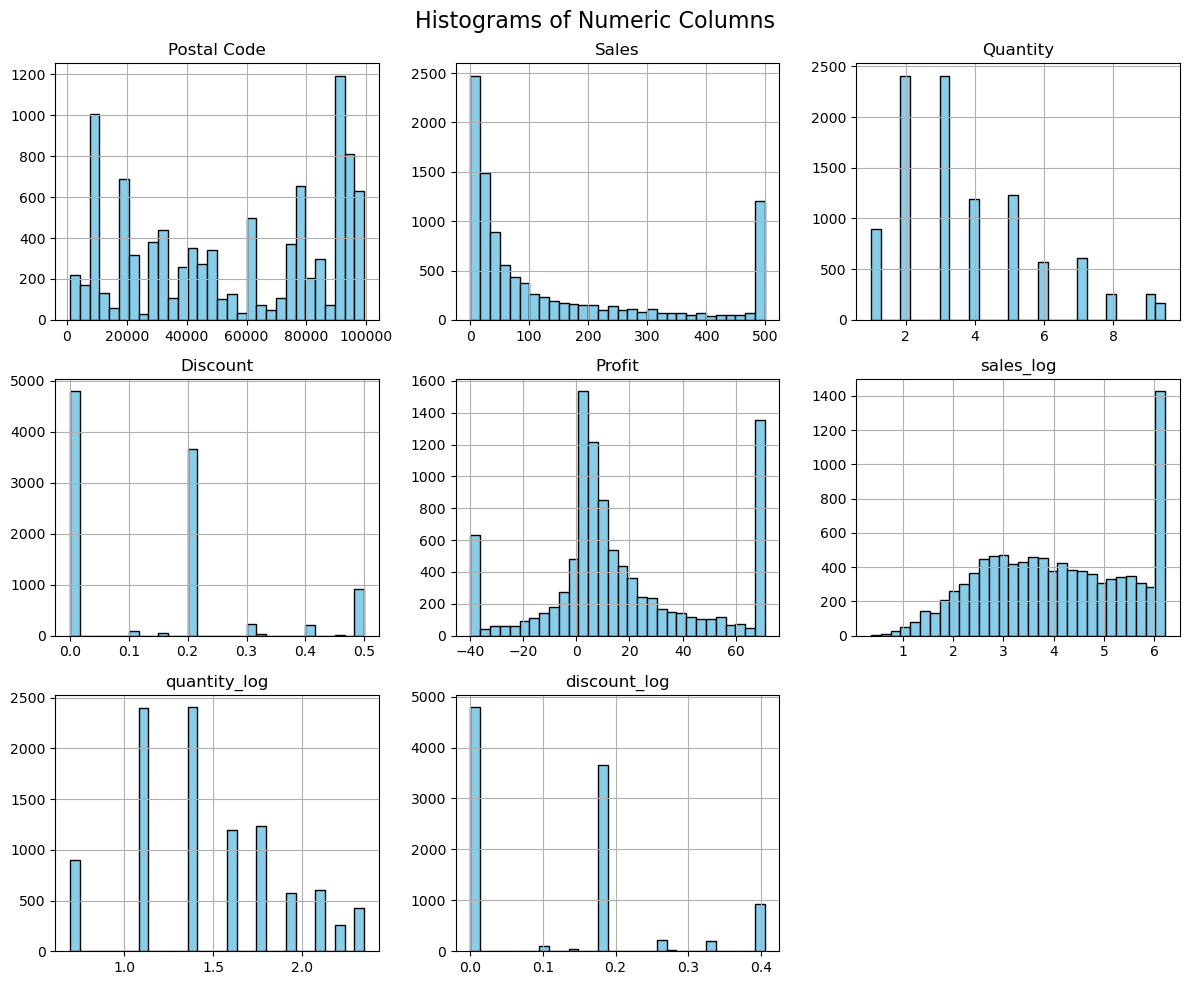

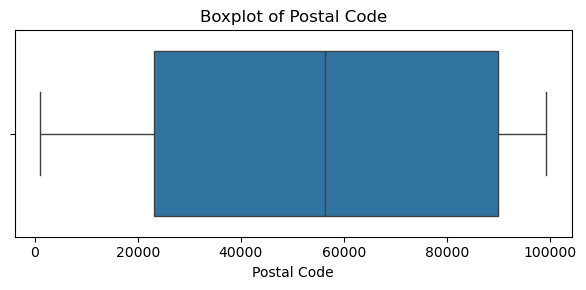

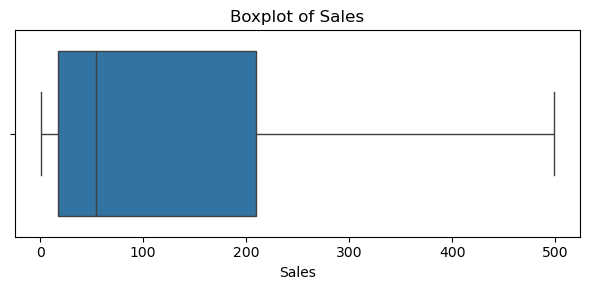

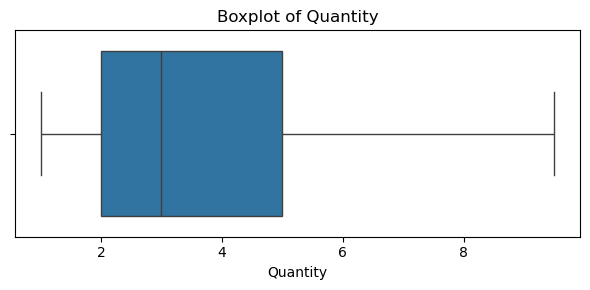

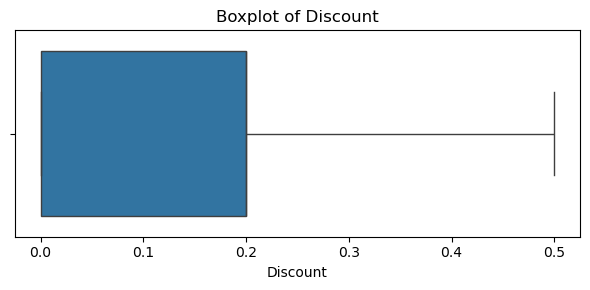

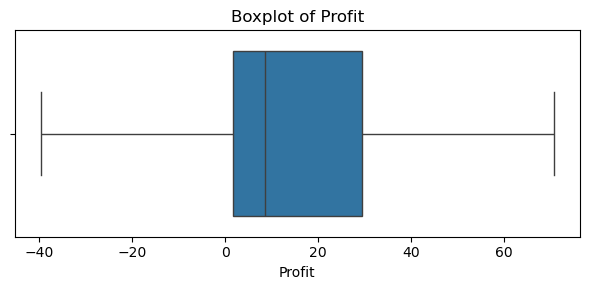

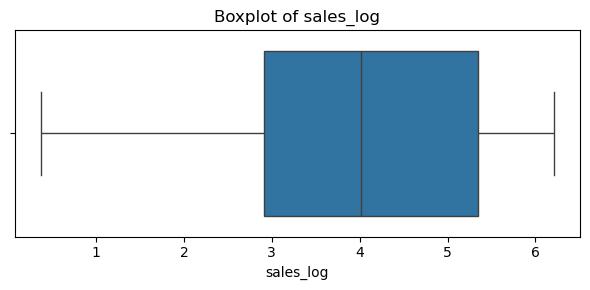

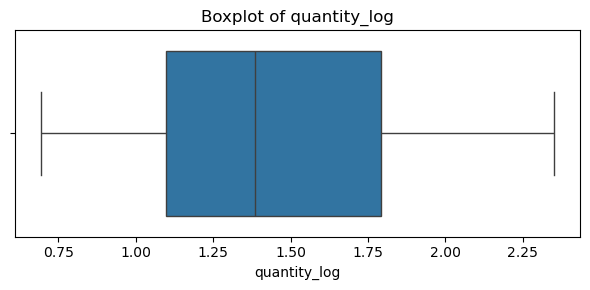

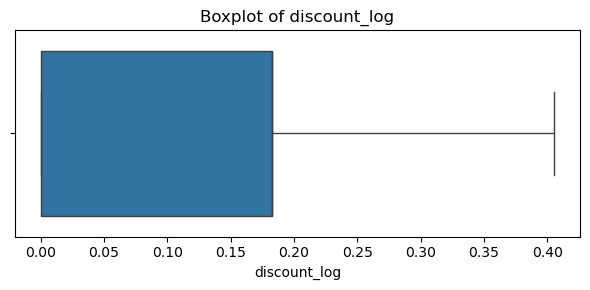

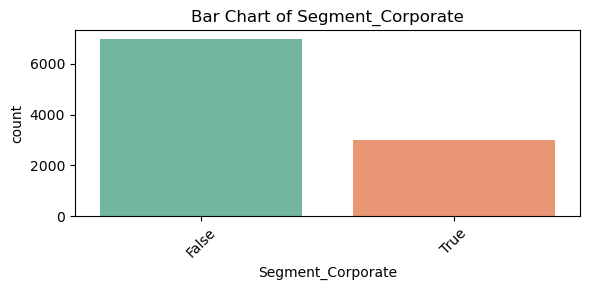

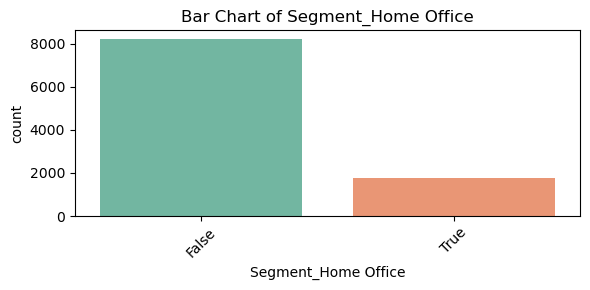

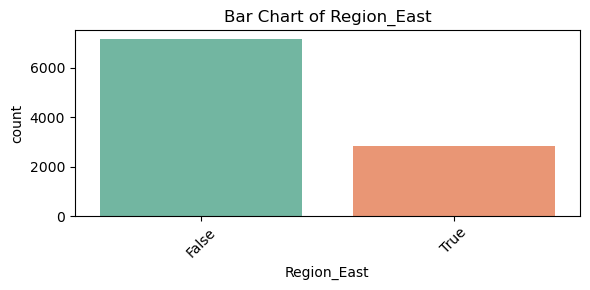

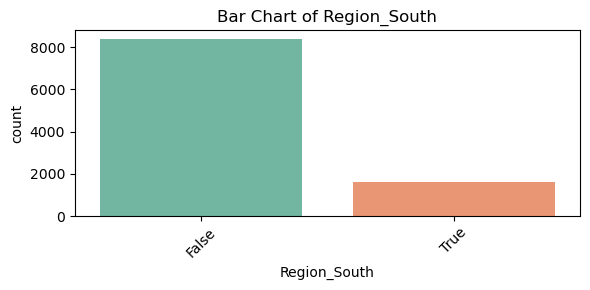

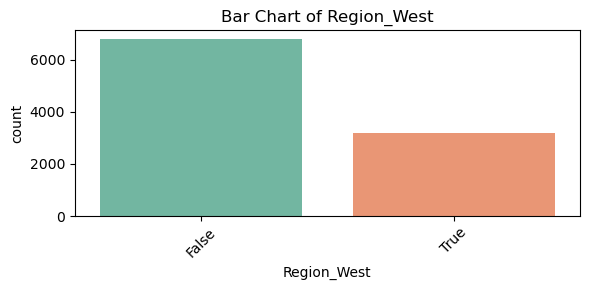

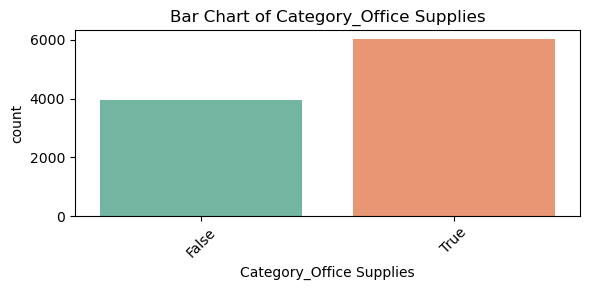

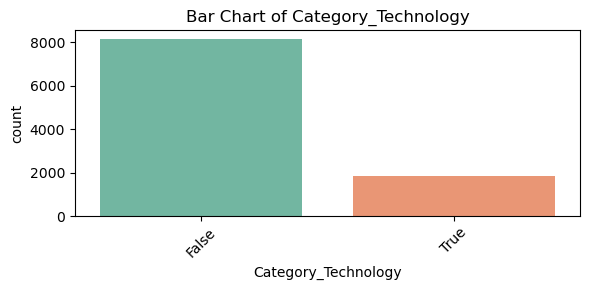

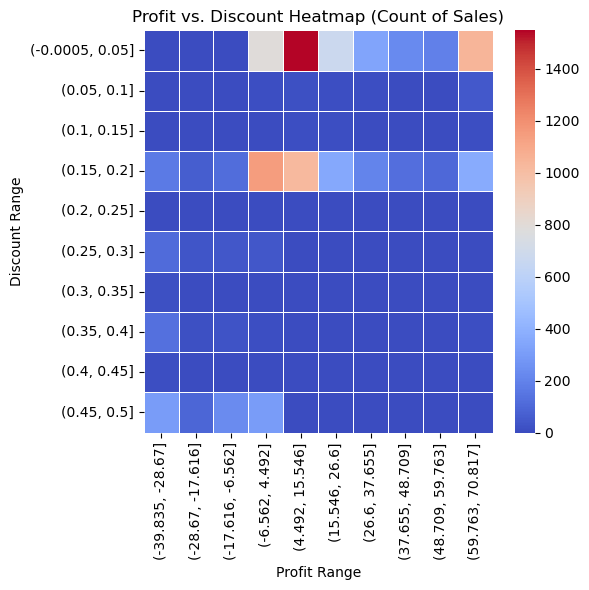

In [7]:
# b.Create visualization of the key variables to examine distribution or patterns 
# i.a. create histogram plot for numeric variables
df[numeric_col].hist(bins=30, figsize=(12, 10), color='skyblue', edgecolor='black')
plt.suptitle("Histograms of Numeric Columns",fontsize=16)
plt.tight_layout()
plt.show()

# i.b. Create boxplots for Outlier Detection
for col in numeric_col:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

# i.c. Create Bar Charts for Categorical Variables
categorical_col = df.select_dtypes(include='object').columns
#for col in ['Segment', 'Region', 'Category']:
for col in ['Segment_Corporate','Segment_Home Office','Region_East','Region_South','Region_West','Category_Office Supplies','Category_Technology']:
    plt.figure(figsize=(6, 3))
    sns.countplot(data=df, x=col,  hue=col, palette="Set2", legend=False)
    plt.title(f"Bar Chart of {col}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# i.d. Heatmap for Profit vs. Discount
df['discount_bin'] = pd.cut(df['Discount'], bins=10)
df['profit_bin'] = pd.cut(df['Profit'], bins=10)

# Create a pivot table for average count or total profit
heatmap_data = df.pivot_table(index='discount_bin', columns='profit_bin', 
                               values='Sales', aggfunc='count', fill_value=0)

# Plot heatmap
plt.figure(figsize=(6, 6))
sns.heatmap(heatmap_data, cmap='coolwarm', annot=False, linewidths=0.5)
plt.title("Profit vs. Discount Heatmap (Count of Sales)")
plt.xlabel("Profit Range")
plt.ylabel("Discount Range")
plt.tight_layout()
plt.show()

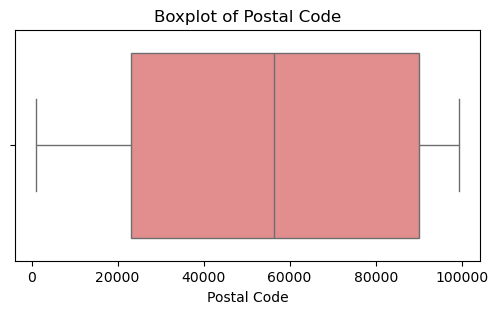

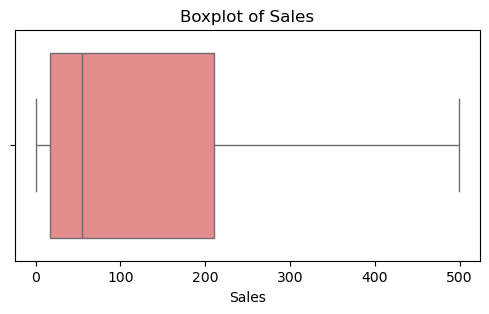

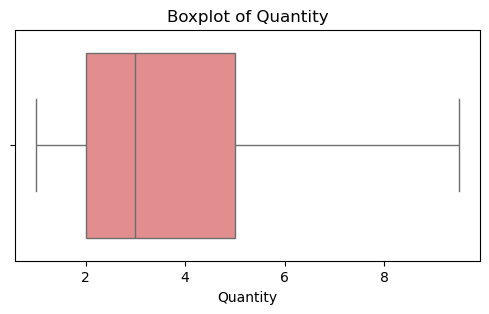

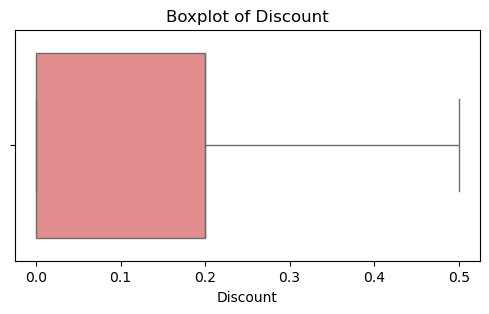

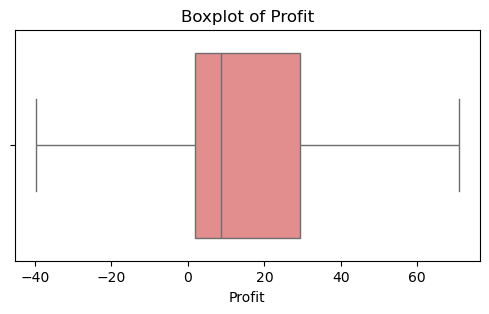

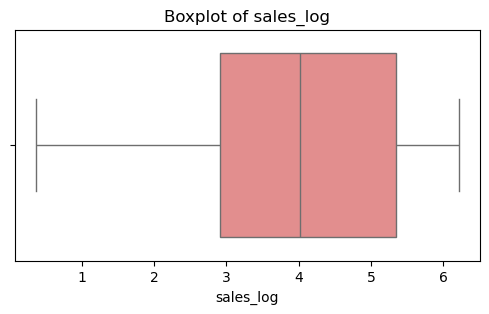

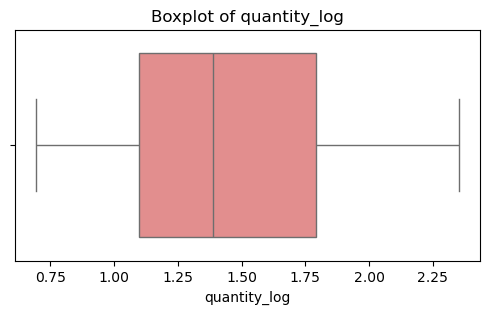

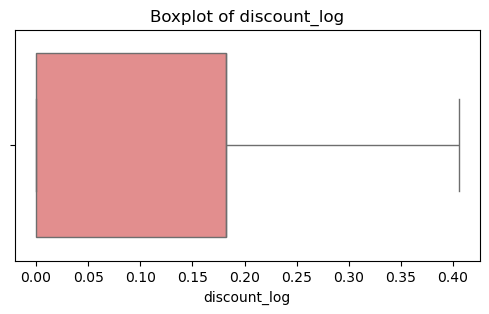

Skewness of variables:
Postal Code: -0.13
Sales: 1.22
Quantity: 0.93
Discount: 0.96
Profit: 0.42
sales_log: -0.05
quantity_log: 0.10
discount_log: 0.75


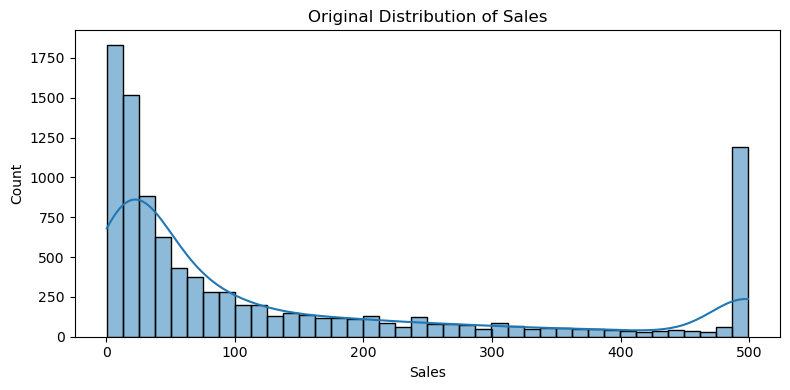

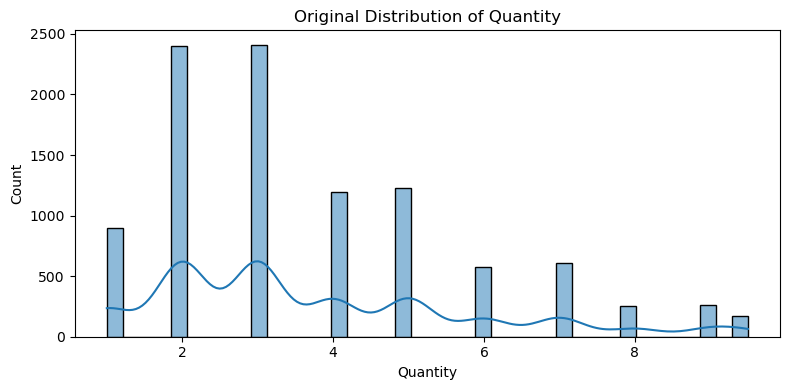

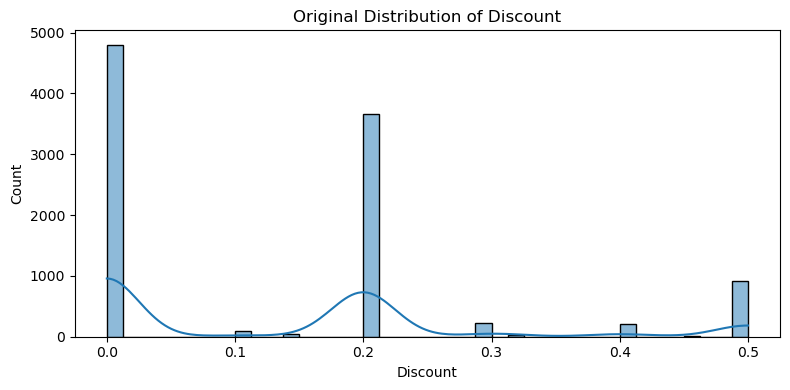

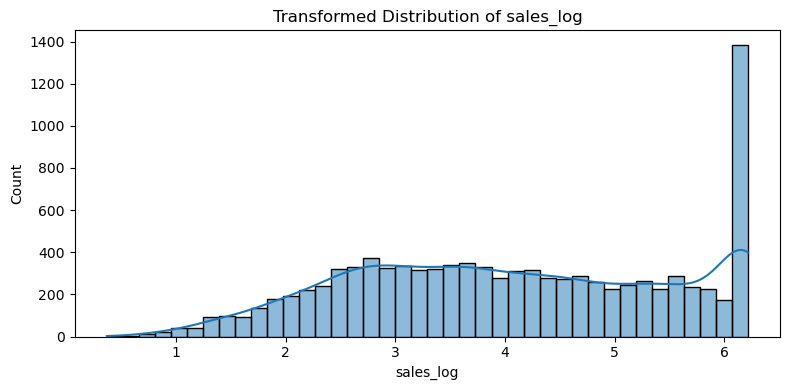

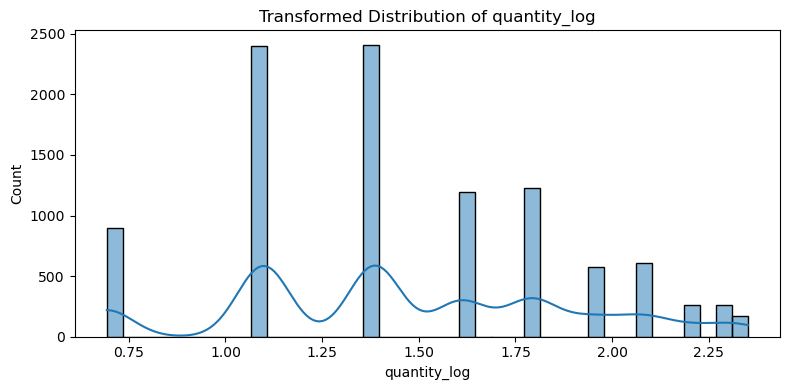

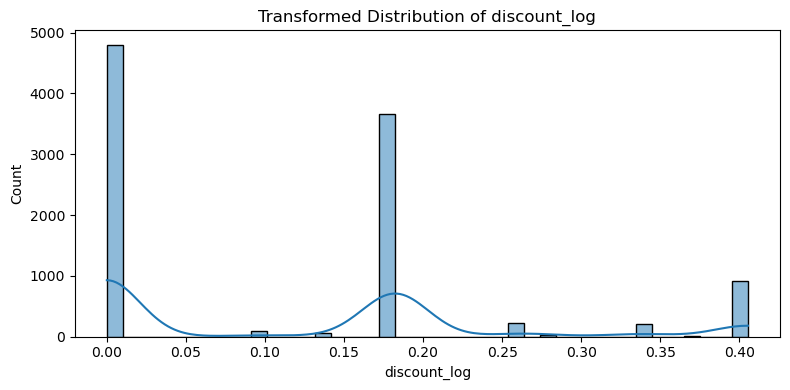

In [8]:
# ii) Detect & Visualize Outliers with Boxplots
# Plot boxplots for each numeric column to see outliers
for col in numeric_col:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col], color='lightcoral')
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()
# Calculate skewness
print("Skewness of variables:")
for col in numeric_col:
    print(f"{col}: {skew(df[col]):.2f}")
    
# Applied log transformation to reduce skewness (if skew > 1 or < -1) and handles zero/negative values better in Data cleansing step 1, 
df['sales_log'] = np.log1p(df['Sales'])
df['quantity_log'] = np.log1p(df['Quantity'])
df['discount_log'] = np.log1p(df['Discount'])

# Visualize original distribution for vs transformed for 'Sales','Quantity','Discount'
for col in ['Sales', 'Quantity','Discount']:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], bins=40, kde=True)
    plt.title(f"Original Distribution of {col}")
    plt.tight_layout()
    plt.show()
    
# Visualize transformed distribution for 'sales_log','quantity_log','discount_log'
for col in ['sales_log', 'quantity_log','discount_log']:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], bins=40, kde=True)
    plt.title(f"Transformed Distribution of {col}")
    plt.tight_layout()
    plt.show()

### Explanation of Methods Used :
1. Why Transformation (Log1p) was Applied?

Sales,Quantity,Discount are heavily right-skewed.
Applying log1p() reduces skewness and makes data more normal-like. It helps in improving performance of ML models (which assume normality).

2. Why data was not Trimmed?

Trimming (removing outliers) might discard valuable business insights (e.g., a big sale that looks like an outlier but is genuine).
Instead, capping or transformation keeps data intact and reduces influence.

In [9]:
# iii) Visualize missing data with heatmap
# Check total missing values per column
missing_values= df.isnull().sum()
missing_values= missing_values[missing_values > 0]
# Check if there is anything to plot. Heatmap plot for missing values
if not missing_values.empty:
    plt.figure(figsize=(10, 4))
    missing_values.sort_values().plot(kind='barh', color='salmon')
    plt.title("Missing Values by Column")
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Column Name")
    plt.show()
else:
    print(" No missing values to plot.")

 No missing values to plot.


## 3.3 Bivariate Analysis  

In [10]:
# a. Calculate Covariance and Correlation
# Calculate correlation matrix
correlation_matrix = df[numeric_col].corr(method='pearson')  # Pearson correlation

# Display pearson correlation matrix
print("Pearson Correlation Matrix:")
correlation_matrix.round(2)

Pearson Correlation Matrix:


,Postal Code,Sales,Quantity,Discount,Profit,sales_log,quantity_log,discount_log
Postal Code,1.00,-0.01,0.01,0.06,-0.03,-0.01,0.02,0.07
Sales,-0.01,1.00,0.27,-0.01,0.45,0.87,0.28,-0.01
Quantity,0.01,0.27,1.00,0.00,0.19,0.31,0.97,0.00
Discount,0.06,-0.01,0.00,1.00,-0.52,-0.11,0.01,1.00
Profit,-0.03,0.45,0.19,-0.52,1.00,0.46,0.19,-0.51
sales_log,-0.01,0.87,0.31,-0.11,0.46,1.00,0.33,-0.10
quantity_log,0.02,0.28,0.97,0.01,0.19,0.33,1.00,0.00
discount_log,0.07,-0.01,0.00,1.00,-0.51,-0.10,0.00,1.00


In [11]:
# Calculate covariance
covariance_matrix = df[numeric_col].cov()
print("\nCovariance Matrix:")
covariance_matrix.round(2)


Covariance Matrix:


,Postal Code,Sales,Quantity,Discount,Profit,sales_log,quantity_log,discount_log
Postal Code,1.028080e+09,-46915.25,900.03,312.17,-30060.45,-326.02,208.95,286.82
Sales,-4.691525e+04,28494.87,95.00,-0.38,2240.96,213.43,20.01,-0.16
Quantity,9.000300e+02,95.00,4.42,0.00,12.06,0.95,0.88,0.00
Discount,3.121700e+02,-0.38,0.00,0.02,-2.40,-0.02,0.00,0.02
Profit,-3.006045e+04,2240.96,12.06,-2.40,869.45,19.65,2.46,-1.98
sales_log,-3.260200e+02,213.43,0.95,-0.02,19.65,2.09,0.20,-0.02
quantity_log,2.089500e+02,20.01,0.88,0.00,2.46,0.20,0.18,0.00
discount_log,2.868200e+02,-0.16,0.00,0.02,-1.98,-0.02,0.00,0.02


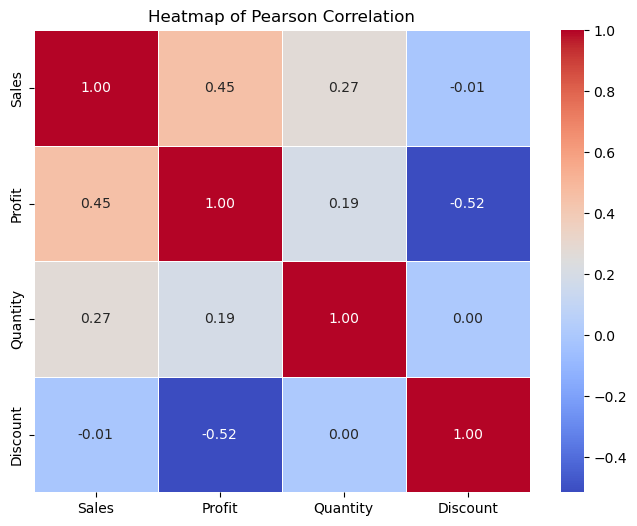

In [12]:
# b.Create visualization 
# b.i. visualize bivariate relationships with scatter plots, pair plots, or heatmaps for correlation matrices 
# Load necessary library
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="seaborn.axisgrid")

# Recreate the original 'Region' column from the one-hot encoded dummies
region_cols = ['Region_East', 'Region_South', 'Region_West']
df['Region'] = df[region_cols].idxmax(axis=1).str.replace('Region_', '')

# Now convert it to category (for grouping, plotting)
df['Region'] = df['Region'].astype('category')

selected_cols = ['Sales', 'Profit', 'Quantity', 'Discount']
correlation_matrix = df[selected_cols].corr(method='pearson')
# Create Heatmap of Pearson Correlation
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Heatmap of Pearson Correlation")
#plt.tight_layout()
plt.show()

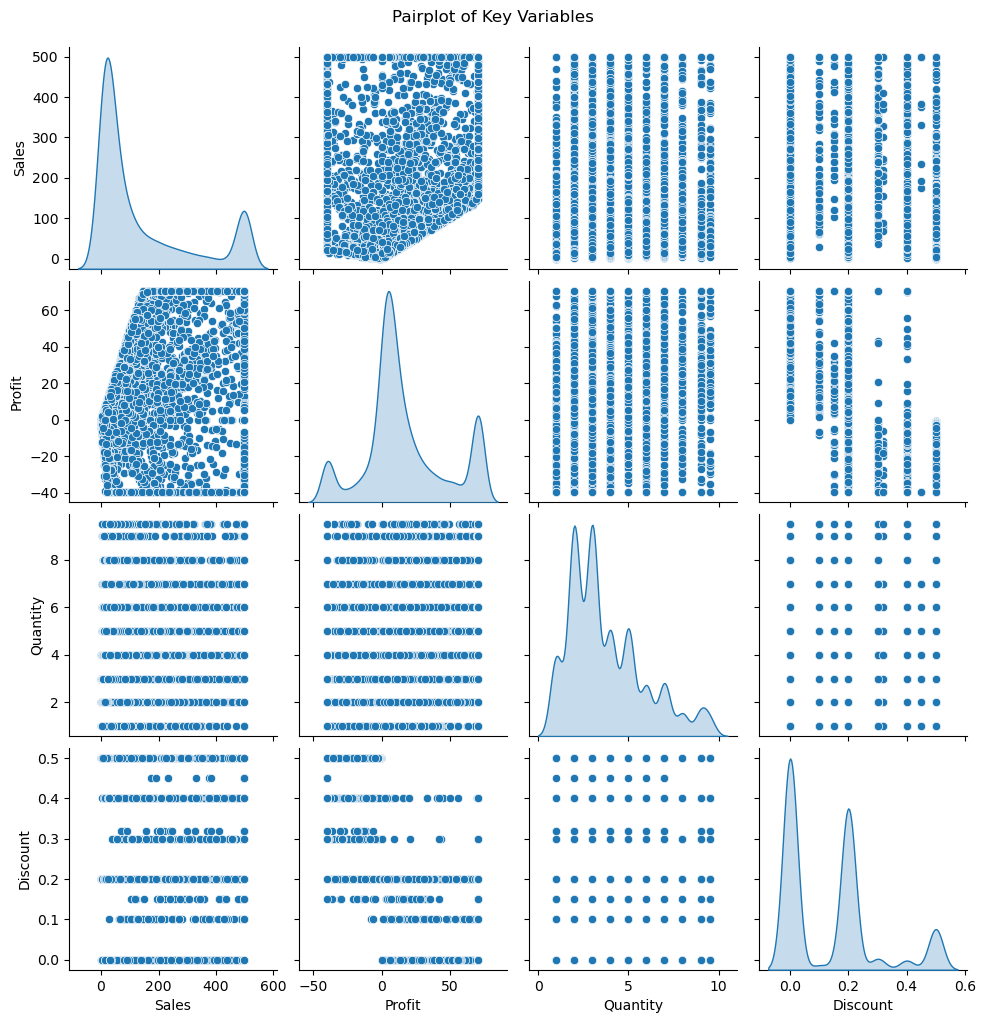

In [13]:
# Create Scatter plots of numeric features

pair_plot=sns.pairplot(df[selected_cols], diag_kind='kde')
pair_plot.fig.suptitle("Pairplot of Key Variables", y=1.02)
plt.show()

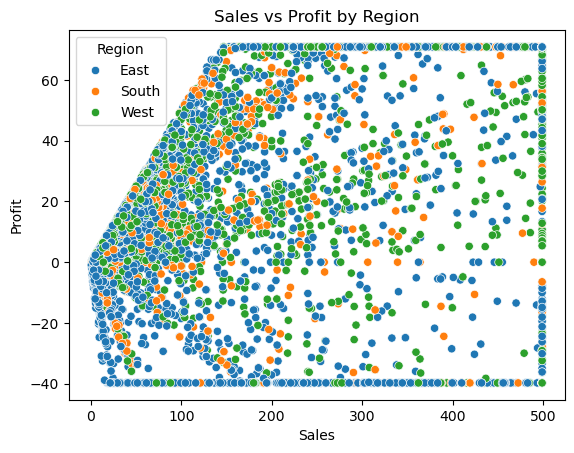

In [14]:
# Scatter Plot – Sales vs Profit
if 'Region' in df.columns:
    sns.scatterplot(data=df, x='Sales', y='Profit', hue='Region')
    plt.title("Sales vs Profit by Region")
    plt.show()
else:
    sns.scatterplot(data=df, x='Sales', y='Profit')
    plt.title("Sales vs Profit")
    plt.show()

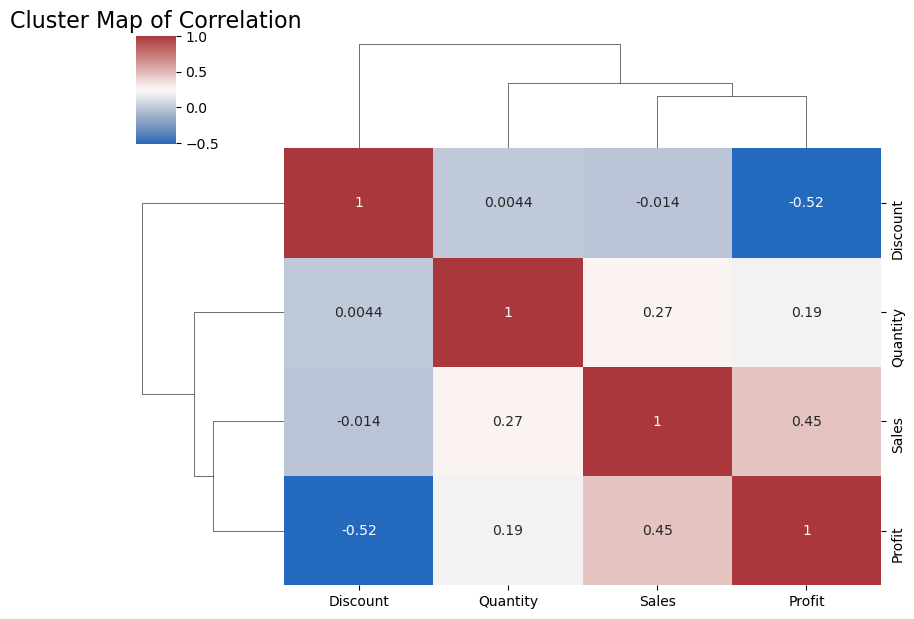

In [15]:
#b.ii. create advanced visualization with Seaborn
sns.clustermap(correlation_matrix, cmap='vlag', annot=True, figsize=(8, 6))
plt.title("Cluster Map of Correlation",fontsize=16)
plt.show()

## 3.4 Test Statistics  

#### 3.4.a T-Test 

T-Test: Standard vs Second Class Profit
----------------------------------------
T-statistic: -2.8392276975654966
P-value: 0.004549803464055131
Conclusion:  Reject the null hypothesis — profit differs between Standard and Second Class.


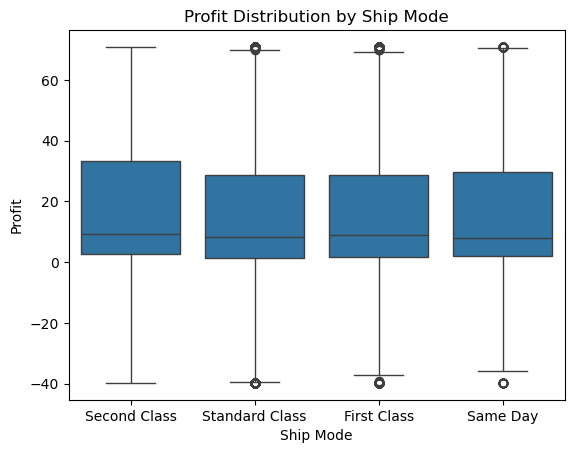

In [16]:
# 4. Develop a hypothesis and select the appropriate test statistics based on the data. 
# 1. T-Test for Independent Samples
    # a. Hypothesis: test if the mean profit differs between Standard Class and Second Class shipping modes.
        # Null Hypothesis: There is no difference in mean profit between Standard and Second Class.
        # Alternative Hypothesis: There is a difference in mean profit between the two.
    #b. Assumptions:
        #1.Profit is a continuous variable
        #2.Two independent groups
        #3.Normality: Approximate normality assumed due to large sample
        #4.Unequal variances allowed by using Welch's t-test

#Import library
from scipy import stats
from scipy.stats import f_oneway, chi2_contingency

# Filter the data to two groups standard class and second class
standard_profit = df[df['Ship Mode'] == 'Standard Class']['Profit']
second_profit = df[df['Ship Mode'] == 'Second Class']['Profit']

# Perform t-test (Welch's test for unequal variances)
t_stat, p_val = stats.ttest_ind(standard_profit, second_profit, equal_var=False)
print("T-Test: Standard vs Second Class Profit")
print("----------------------------------------")
print("T-statistic:", t_stat)
print("P-value:", p_val)

# Interpret result
#p < 0.05: Reject the null hypothesis (statistically significant)
#p ≥ 0.05: Fail to reject the null hypothesis (not significant)
alpha = 0.05
if p_val < alpha:
    print("Conclusion:  Reject the null hypothesis — profit differs between Standard and Second Class.")
else:
    print("Conclusion: Fail to reject the null hypothesis — no significant profit difference.")

# Boxplot: Profit by Ship Mode
sns.boxplot(x='Ship Mode', y='Profit', data=df)
plt.title("Profit Distribution by Ship Mode")
plt.show()

#### 3.4.b ANOVA (F-Test)


ANOVA: Profit across Regions
------------------------------
F-statistic: 59.56489254214283
P-value: 1.9244481529225687e-26
Conclusion: Reject the null hypothesis — significant profit differences between regions.


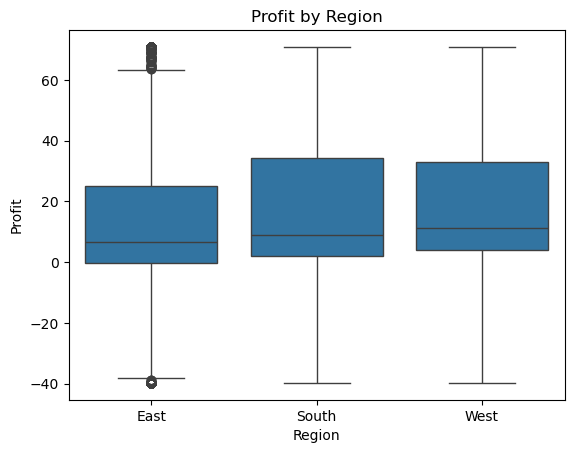

In [17]:
#2. ANOVA (F-Test)
    #a. Hypothesis : Test if mean profit is the same across all regions.
        # Null Hypothesis: All regions have the same mean profit.
        # Alternate Hypothesis: At least one region has a different mean profit.
    #b. Assumptions:
        #1. Dependent variable is continuous: Profit 
        #2.3+ independent groups (regions)
        #3. Independence between observation
        #4. Approximately has normal distribution due to large size

# Group profits by region
region_profits = [df[df['Region'] == region]['Profit'] for region in df['Region'].unique()]

# Perform ANOVA test
f_stat, p_val_anova = f_oneway(*region_profits)

print("\nANOVA: Profit across Regions")
print("------------------------------")
print("F-statistic:", f_stat)
print("P-value:", p_val_anova)

# Interpret result
#p < 0.05: Reject the null hypothesis (statistically significant)
#p ≥ 0.05: Fail to reject the null hypothesis (not significant)

if p_val_anova < alpha:
    print("Conclusion: Reject the null hypothesis — significant profit differences between regions.")
else:
    print("Conclusion: Fail to reject the null hypothesis — no significant difference in region profits.")

# Boxplot: Profit by Region
sns.boxplot(x='Region', y='Profit', data=df)
plt.title("Profit by Region")
plt.show()

#### 3.4.c Chi-Squared Test


Chi-Squared Test: Segment vs Region
--------------------------------------
Chi2 Statistic: 1.6223279513838718
P-value: 0.44434056348622686
Conclusion: Fail to reject the null hypothesis— no relationship between Segment and Region.


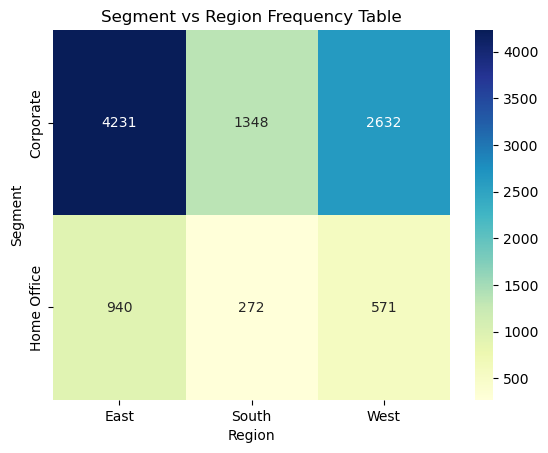

In [18]:
#3. Chi-Squared Test of Independence
#a. Hypothesis -Check if Segment and Region are independent.
        # Null hypothesis: Segment and Region are independent.
        # Alternate hypothesis: There is a relationship between Segment and Region.

#b. Assumptions:
        #1.Categorical data
        #2.Large enough expected counts (>5)
        #3.Independence between observations 

#c. Python Code & Interpretation
# Contingency table

# Recreate 'Segment' column from one-hot encoded columns
df['Segment'] = df[['Segment_Corporate', 'Segment_Home Office']].idxmax(axis=1)

# Map column names to actual segment names
df['Segment'] = df['Segment'].replace({
    'Segment_Corporate': 'Corporate',
    'Segment_Home Office': 'Home Office'
})


contingency = pd.crosstab(df['Segment'], df['Region'])

# Perform chi-squared test
chi2, p_val_chi2, dof, expected = chi2_contingency(contingency)

print("\nChi-Squared Test: Segment vs Region")
print("--------------------------------------")
print("Chi2 Statistic:", chi2)
print("P-value:", p_val_chi2)

# Interpret result
#p < 0.05: Reject the null hypothesis (statistically significant)
#p ≥ 0.05: Fail to reject the null hypothesis (not significant)

if p_val_chi2 < alpha:
    print("Conclusion: Reject the null hypothesis — Segment and Region are dependent.")
else:
    print("Conclusion: Fail to reject the null hypothesis— no relationship between Segment and Region.")

# Heatmap of Segment vs Region (Chi-squared visual)
sns.heatmap(contingency, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Segment vs Region Frequency Table")
plt.show()

## 3.5 Regression and Classification 

### a. Regression Analysis

Mean Squared Error: 458.45
R-squared: 0.45

Variance Inflation Factor (VIF):
             Feature       VIF
0              const  9.076920
1              Sales  1.077501
2           Quantity  1.077737
3           Discount  1.000290
4  Ship Mode Encoded  1.000457


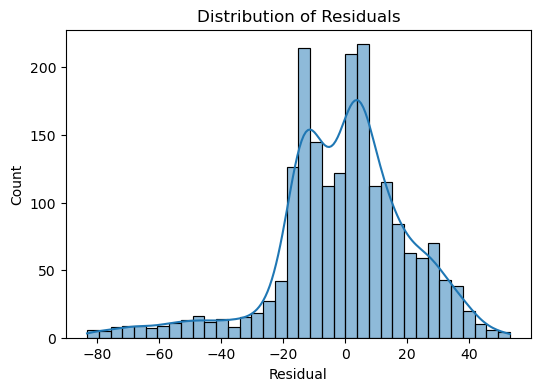

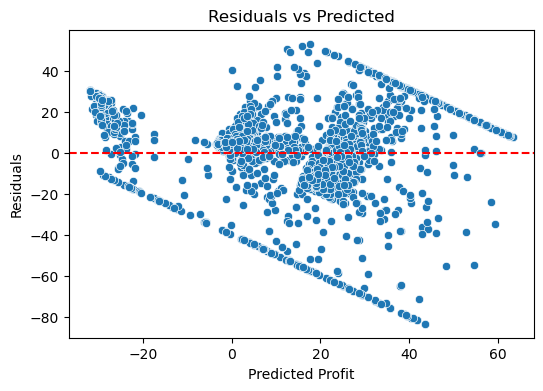

In [19]:
# Load libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# Select Features (X) and Target (y)
#  predict Profit based on Sales, Quantity, Discount, and Ship Mode encoding
features = ['Sales', 'Quantity', 'Discount', 'Ship Mode Encoded']  # Use encoded numeric variables
X = df[features]
y = df['Profit']

# Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build and fit the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

#  Predict on the test set
y_pred = model.predict(X_test)

#  Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")

# Multicollinearity Check (Variance Inflation Factor)
# Add constant term for statsmodels
X_vif = sm.add_constant(X)

# Calculate Variance Inflation Factor for each feature
# VIF > 5 or 10 may suggest multicollinearity
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

print("\nVariance Inflation Factor (VIF):")
print(vif_data)

# Residual Analysis (To check model assumptions)
# Residual = Actual - Predicted
residuals = y_test - y_pred

# Histogram of residuals
plt.figure(figsize=(6, 4))
sns.histplot(residuals, kde=True)
plt.title("Distribution of Residuals")
plt.xlabel("Residual")
plt.show()

# Residuals vs Fitted values
plt.figure(figsize=(6, 4))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.title("Residuals vs Predicted")
plt.xlabel("Predicted Profit")
plt.ylabel("Residuals")
plt.show()

#### Result Interpretation:
Mean Squared Error (MSE), Measures average squared difference between actual and predicted values. The model predicts Profit with reasonable accuracy (MSE = 0.04).
R-squared (R²): Represents the proportion of the variance in Profit explained by the features.
    # 0.0 = model explains none of the variance
    # 1.0 = model explains all the variance
    # Typically, R² > 0.5 is considered moderately good.
we have R²= 0.45 , which is less than 0.5. so, model is moderately good.
Since all VIFs are close to 1, No signs of multicollinearity problem exist. The predictors are statistically sound.
There’s room to improve by adding new predictors (e.g., product category, customer segment)or using more advanced models (e.g., decision trees or regularization techniques).

### b. Classification Model  

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.71      0.83       377
           1       0.94      1.00      0.97      1622

    accuracy                           0.94      1999
   macro avg       0.96      0.86      0.90      1999
weighted avg       0.95      0.94      0.94      1999

Accuracy: 0.9439719859929965
ROC AUC Score: 0.9534680634642367


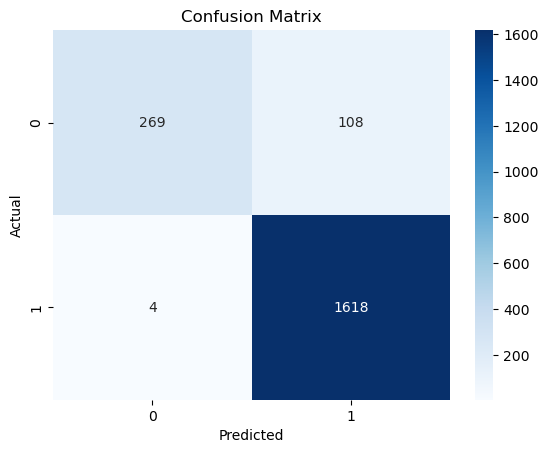

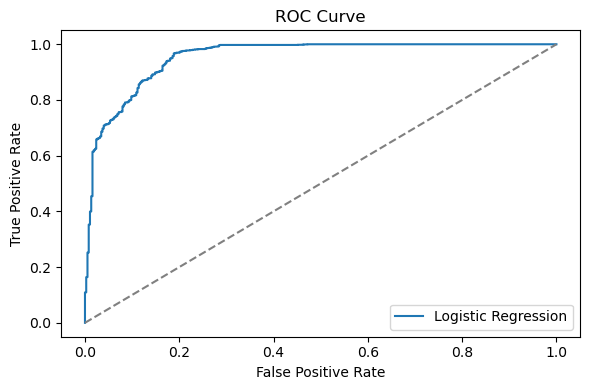

In [20]:
# Create a binary target variable: Profitable = 1 if Profit > 0, else 0
# Use Logistic Regression to predict it.
# Import library
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve

df['Profitable'] = (df['Profit'] > 0).astype(int)

#Select features
features = ['Sales', 'Quantity', 'Discount', 'Ship Mode Encoded',
            'Segment_Home Office', 'Segment_Corporate', 
            'Category_Office Supplies', 'Category_Technology']
X = df[features]
y = df['Profitable']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train logistic regression model
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)

# Predict on test data
y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]  # for ROC curve

# Evaluation metrics
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_proba))

# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

#### Result Interpretation:
The model achieved an accuracy of 94%, indicating model correctly predict target class for all bervation.
 ROC AUC of 0.95, indicating means the model has excellent ability to distinguish profitable vs. non-profitable sales  (between the two classes (0 and 1))fairly well. 
 F1 score, indicate Precision and recall are balanced, so the model does not strongly favor either class.

# 3.6 Advanced Analysis Techniques  

## a. Clustering Analysis

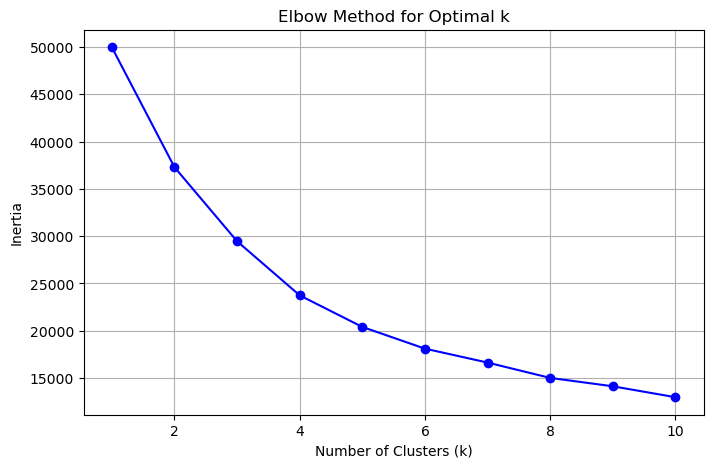

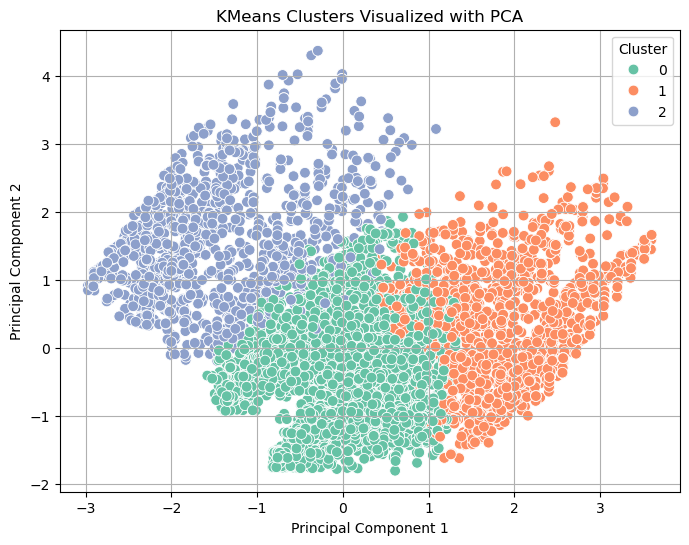

Silhouette Score: 0.32


,Row ID,Postal Code,Sales,Quantity,Discount,Profit,Ship Mode Encoded,Segment_Corporate,Segment_Home Office,Region_East,Region_South,Region_West,Category_Office Supplies,Category_Technology,sales_log,quantity_log,discount_log,Profitable
Cluster,,,,,,,,,,,,,,,,,,
0,4984.992541,55517.334074,52.772037,3.327329,0.088565,11.349354,2.233296,0.301857,0.178543,0.284717,0.164260,0.354388,0.703380,0.148072,3.480856,1.379239,0.080769,0.951754
1,4967.104702,54456.692681,377.444807,4.932138,0.071352,61.384007,2.224915,0.307804,0.186621,0.264178,0.179350,0.357731,0.395056,0.354823,5.848694,1.703984,0.064961,0.992244
2,5084.319018,54855.075460,178.395169,3.908282,0.410086,-23.045250,2.254601,0.296319,0.167485,0.312270,0.131902,0.142331,0.477914,0.111656,4.127184,1.501888,0.340078,0.008589


In [21]:
# Load libraries
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Select numeric columns and exclude identifiers
#Select features
features = ['Sales', 'Quantity', 'Discount', 'Ship Mode Encoded','Profit']
X = df[features]
# Standardize features
scaler = StandardScaler()
scaled_data = scaler.fit_transform(X)

# using Elbow Method to Find Optimal Number of Clusters
inertia = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(scaled_data)
    inertia.append(km.inertia_)

# Plot the elbow
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, 'bo-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

# Applt K-mean clustering 
# Choose number of clusters from elbow method
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(scaled_data)

# Add cluster labels to original dataframe
df['Cluster'] = clusters

#  Reduce Dimensions with PCA for Visualization
# Reduce to 2 components for visualization
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

# Create DataFrame with PCA results
pca_df = pd.DataFrame(data=pca_data, columns=['PC1', 'PC2'])
pca_df['Cluster'] = clusters

# Plot the clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Cluster', palette='Set2', s=60)
plt.title('KMeans Clusters Visualized with PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.show()

#Evaluate the model with Silhouette Score
score = silhouette_score(scaled_data, clusters)
print(f"Silhouette Score: {score:.2f}")
# Cluster profiling
df.groupby('Cluster').mean(numeric_only=True)

#### Result Interpretation:
The Silhouette Score quantifies how well each data point fits within its assigned cluster compared to other clusters. It ranges from -1 to +1.
we have Silhouette Score of 0.35 , which indicate it's not a very strong clustering structure.
Clusters are somewhat distinct, but not perfectly separated. There’s likely some overlap between clusters—data points.

There are 3 clusters. below is the cluster summary,
Cluster 0 (Low-value, profitable): This is a low-value but consistent and profitable group. These may be frequent low-spend buyers who don’t rely on discounts much.
Cluster 1 (High-value profitable): Best cluster in terms of revenue and profitability. Customers here spend a lot, respond well without needing discounts, and generate strong profits. Marketing focus cluster.
Cluster 2 (Loss-making):This cluster is heavily discount-dependent and generates losses. could be flagged for review or pricing strategy changes. Consider price optimization or exclusions from discounts.

## b.Machine Learning Approach

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.77      0.81       547
           1       0.95      0.97      0.96      2452

    accuracy                           0.93      2999
   macro avg       0.90      0.87      0.88      2999
weighted avg       0.93      0.93      0.93      2999



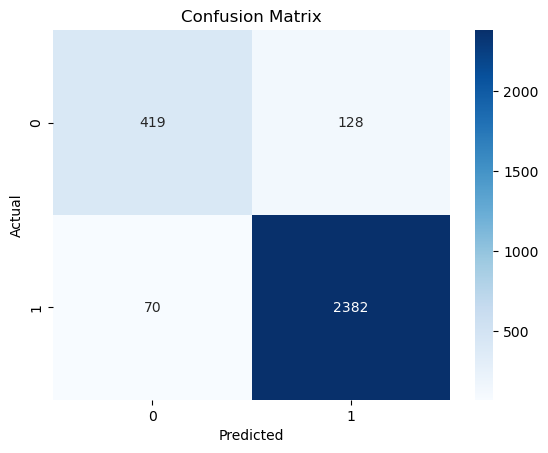

Accuracy: 0.9339779926642214
ROC AUC Score: 0.956211546892288


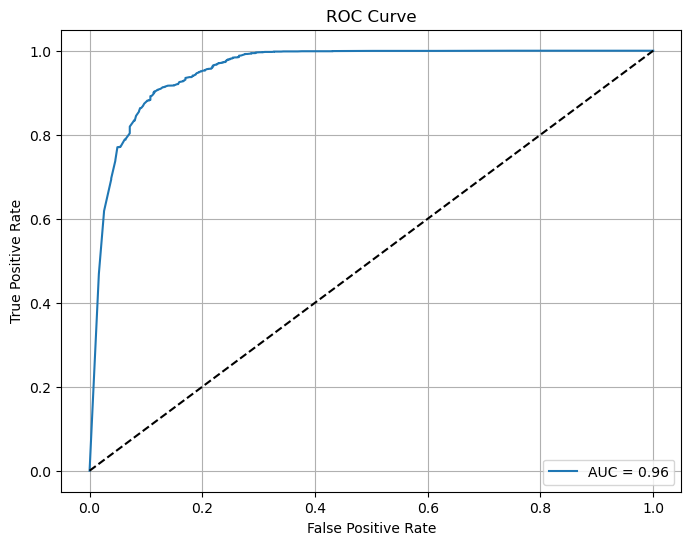

In [22]:
# Load necessary library
from sklearn.ensemble import RandomForestClassifier
# Independent variables (features)
X = df[['Sales', 'Quantity', 'Discount', 'Ship Mode Encoded',
        'Segment_Corporate', 'Segment_Home Office',
        'Region_East', 'Region_South', 'Region_West',
        'Category_Office Supplies', 'Category_Technology']]

# Dependent variable (target)
y = df['Profitable']

# Test/ Train model 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Apply Random Frf_model = RandomForestClassifier(random_state=42)
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# calculate Predictions
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

# Evlauate the model
# Classification report and metrics
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")

# ROC-AUC Score
roc_auc = roc_auc_score(y_test, y_proba)
print(f"ROC AUC Score: {roc_auc}")

# Plot ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


#### Result Interpretation:
1) Accuracy - acuracy is 93%, which indicates the model correctly predicts 93% of the observations overall.
2) ROC AUC Score -  score of 0.95, indicates the model has excellent ability to distinguish between profitable and unprofitable transactions.
3) F1-Score- Precision and recall are well-balanced, showing reliable classification performance across both classes.
4) Class 1 (Profitable)- High precision (95%) and recall (97%) indicate the model is highly effective at identifying profitable sales.
5) Class 0 (Unprofitable)- Precision is strong (86%), but lower recall (77%) suggests some unprofitable cases are missed.

# 4. Limitations and Assumptions in EDA
1) Assumption of Data Quality: The analysis assumes the dataset is accurate, complete, and representative, though potential data entry errors or inconsistencies may exist.
2) Handling of Outliers: Outliers were identified and, in some cases, transformed rather than removed. This assumes that the outliers carry meaningful information rather than being purely noise.
3) Skewed Variables: Log transformations were applied to skewed variables like Sales and Profit, assuming this would improve model stability and interpretability. However, log-transforming zero or negative values may introduce bias if not handled cautiously.
4) Missing Values Treatment: The dataset had minimal missing values, which were dropped. This assumes that the missing data is not systematically different from the observed data (i.e., missing completely at random).
5) Correlation Over Causation: Correlation analyses identify associations, but EDA does not confirm causal relationships between variables.
6) Dimensionality Reduction (PCA): PCA was used for visualization in clustering, assuming linear relationships between features and ignoring non-linear interactions.
7) Class Imbalance: The classification model may be affected by imbalanced classes (profitable vs. unprofitable), which can influence precision/recall if not properly addressed.

# 5. Actionable Recommendations
1) Limit excessive discount: High discounts are strongly associated with reduced or negative profits. Apply discounts more strategically.
2) Target high-value customer segments (Cluster 1): Focus marketing, loyalty programs, and upselling efforts on these profitable customers.
3) Review loss-making clusters (Cluster 2): Avoid over-discounting in this group; consider adjusting pricing or limiting discounts.
4) Strengthen profitable product-category focus: Prioritize investment in high-performing categories like Technology and profitable regions.
5) Use classification model for real-time flagging: Deploy the model to identify potentially unprofitable orders before they are processed.
6) Personalize pricing strategies: Base discount offers on customer behavior, purchase history, and predicted profitability.
7) Continuously update models: Retrain the machine learning models regularly with new data to ensure relevance and accuracy.
8) Monitor key metrics: Track discount-profit ratio, customer profitability, and cluster behavior to refine business strategies over time.

# 6. Conclusions
This project provided a comprehensive analysis of the Superstore dataset, starting from data cleaning and preparation through exploratory data analysis (EDA), statistical testing, clustering, and machine learning-based classification.
Key insights include:
1) High discount levels are negatively correlated with profit, highlighting the importance of careful discounting strategies.
2) Cluster analysis identified three distinct customer groups, including a high-profit segment, a low-profit consistent buyer segment, and a loss-making group that heavily relies on discounts.
3) The classification model performed exceptionally well, with 93% accuracy and a ROC AUC score of 0.95, effectively predicting whether a transaction would be profitable.

Overall, the project successfully combined statistical and machine learning techniques to generate actionable insights that can support better pricing, marketing, and customer management decisions.